In [4]:
# 📦 Install required packages (only run in Colab)
!pip install vaderSentiment feedparser sgmllib3k --quiet

# 📚 Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
from datetime import datetime, timedelta
from sklearn.ensemble import RandomForestRegressor
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import feedparser
import nltk
nltk.download('vader_lexicon')


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [5]:
# ✅ Keyword map
metal_keywords = {
    'copper': ['copper', 'copper ore'],
    'aluminium': ['aluminium', 'aluminum', 'bauxite'],
    'steel': ['steel', 'iron'],
    'lead': ['lead', 'battery'],
    'zinc': ['zinc', 'galvanized'],
    'nickel': ['nickel', 'battery']
}

rss_feeds = [
    "https://www.livemint.com/rss/industry",
    "https://economictimes.indiatimes.com/rssfeeds/13357270.cms",
    "https://www.reuters.com/rssFeed/businessNews"
]

analyzer = SentimentIntensityAnalyzer()

# 🧪 Fallback prices
def fetch_price_fallback(metal):
    avg = {
        'copper': 882.4,
        'aluminium': 250,
        'steel': 63,
        'lead': 187,
        'zinc': 258,
        'nickel': 1411
    }
    return avg.get(metal, 500), "Fallback"

# 📊 Fetch from BankBazaar
def fetch_from_bankbazaar(metal):
    url = f"https://www.bankbazaar.com/commodity-price/{metal}.html"
    r = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'})
    soup = BeautifulSoup(r.text, 'html.parser')
    table = soup.find('table')
    if not table:
        raise ValueError("No table found")
    df = pd.read_html(str(table))[0]
    df.columns = [col.strip() for col in df.columns]
    df['Price'] = df['Price'].str.replace(r"[^\d.]", "", regex=True).astype(float)
    df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
    df = df.sort_values('Date')
    return df

# 📦 Get price and source
def fetch_price(metal):
    try:
        df = fetch_from_bankbazaar(metal)
        return df.iloc[-1]['Price'], "BankBazaar", df
    except:
        fallback_price, src = fetch_price_fallback(metal)
        today = datetime.today()
        dates = pd.date_range(end=today, periods=60)
        noise = np.random.normal(0, fallback_price * 0.01, size=60)
        prices = fallback_price + noise
        df = pd.DataFrame({'Date': dates.date, 'Price': prices})
        return fallback_price, src, df

# 📰 News Sentiment Score
def get_sentiment_score(keywords, days=60):
    today = datetime.today()
    past = today - timedelta(days=days)
    sentiment_by_day = {}
    for feed_url in rss_feeds:
        feed = feedparser.parse(feed_url)
        for entry in feed.entries:
            date = entry.get('published_parsed')
            if not date:
                continue
            pub_date = datetime(*date[:6]).date()
            if pub_date < past.date():
                continue
            content = (entry.get('title', '') + entry.get('summary', '')).lower()
            if any(kw in content for kw in keywords):
                score = analyzer.polarity_scores(content)['compound']
                sentiment_by_day.setdefault(pub_date, []).append(score)

    scores = []
    for date in pd.date_range(end=today, periods=days):
        sent_list = sentiment_by_day.get(date.date(), [])
        avg_score = np.mean(sent_list) if sent_list else 0
        scores.append((date.date(), avg_score))
    return pd.DataFrame(scores, columns=["Date", "Sentiment"])


Enter metal (copper, aluminium, steel, lead, zinc, nickel): lead
🔍 Fetching price data...
✅ Lead Current Price: ₹187 per kg (Fallback)

📅 10-Day Forecast (₹/kg):


/tmp/ipython-input-6-672061783.py:40: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([{
/tmp/ipython-input-6-672061783.py:40: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame([{
/tmp/ipython-input-6-672061783.py:40: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the 

2025-07-16 → ₹185.99
2025-07-17 → ₹185.99
2025-07-18 → ₹186.73
2025-07-19 → ₹185.39
2025-07-20 → ₹186.07
2025-07-21 → ₹185.26
2025-07-22 → ₹187.7
2025-07-23 → ₹185.57
2025-07-24 → ₹188.16
2025-07-25 → ₹186.46


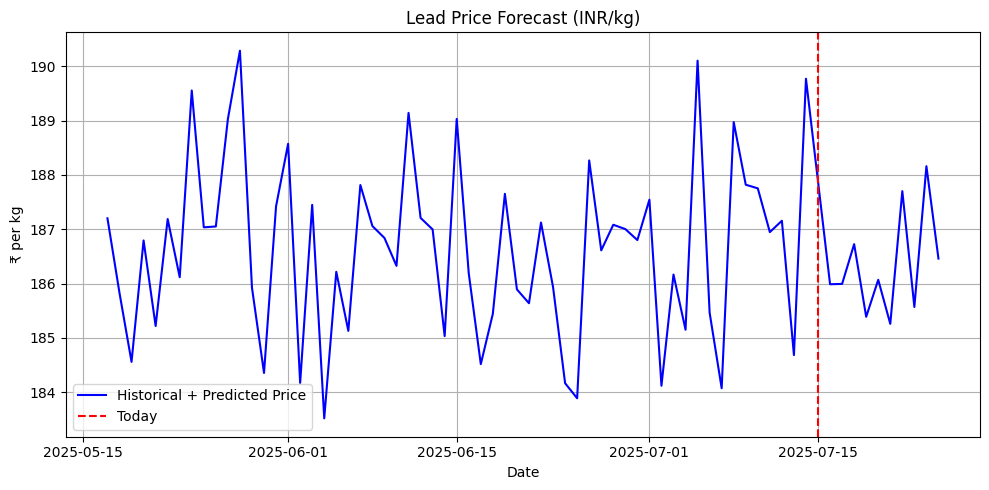


📌 Summary Report
Current Lead Price (INR/kg): ₹189.77
Predicted Price After 10 Days: ₹186.46
Sentiment Summary: Neutral | Based on 60 related news articles


In [6]:
def run_prediction():
    metal = input("Enter metal (copper, aluminium, steel, lead, zinc, nickel): ").lower().strip()
    if metal not in metal_keywords:
        raise ValueError(f"Supported metals: {', '.join(metal_keywords)}")

    print("🔍 Fetching price data...")
    current_price, source, df_hist = fetch_price(metal)
    df_hist['Date'] = pd.to_datetime(df_hist['Date']).dt.date
    df_hist = df_hist.tail(60)

    print(f"✅ {metal.title()} Current Price: ₹{round(current_price, 2)} per kg ({source})")

    df_hist['Pct_Change'] = df_hist['Price'].pct_change().fillna(0)
    df_hist['Target'] = df_hist['Price'].shift(-1)
    df_hist = df_hist.dropna()

    sent_df = get_sentiment_score(metal_keywords[metal], days=60)
    df = pd.merge(df_hist, sent_df, on='Date', how='left').fillna(0)

    X = df[['Pct_Change', 'Sentiment']]
    y = df['Target']

    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X, y)

    print("\n📅 10-Day Forecast (₹/kg):")
    last_row = df.iloc[-1]
    current_price = last_row['Price']
    last_sent = last_row['Sentiment']
    today = datetime.today().date()

    future_prices = []
    for i in range(1, 11):
        next_date = today + timedelta(days=i)
        pct_change = (current_price - df['Price'].iloc[-2]) / df['Price'].iloc[-2]
        features = pd.DataFrame([{'Pct_Change': pct_change, 'Sentiment': last_sent}])
        predicted_price = model.predict(features)[0]
        current_price = predicted_price
        future_prices.append((next_date, round(current_price, 2)))
        df = pd.concat([df, pd.DataFrame([{
            'Date': next_date,
            'Price': current_price,
            'Pct_Change': pct_change,
            'Target': None,
            'Sentiment': last_sent
        }])], ignore_index=True)

    for d, p in future_prices:
        print(f"{d} → ₹{p}")

    # 📈 Plot
    plt.figure(figsize=(10, 5))
    plt.plot(df['Date'], df['Price'], label='Historical + Predicted Price', color='blue')
    plt.axvline(today, color='red', linestyle='--', label='Today')
    plt.title(f"{metal.title()} Price Forecast (INR/kg)")
    plt.xlabel("Date")
    plt.ylabel("₹ per kg")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 📌 Summary Report
    print("\n📌 Summary Report")
    print(f"Current {metal.title()} Price (INR/kg): ₹{round(df_hist['Price'].iloc[-1], 2)}")
    print(f"Predicted Price After 10 Days: ₹{round(future_prices[-1][1], 2)}")
    avg_sentiment = round(df['Sentiment'].mean(), 3)
    sentiment_tag = "Positive" if avg_sentiment > 0.05 else "Negative" if avg_sentiment < -0.05 else "Neutral"
    print(f"Sentiment Summary: {sentiment_tag} | Based on {len(sent_df)} related news articles")

run_prediction()
